# Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import *

## 1. Import dataset & Bar-plot for imbalanced classes

In [4]:
df_train = pd.read_csv("train.csv")

print("Train set")
display(df_train.head())
print(df_train.shape)

Train set


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


(7613, 5)


They contain:

- id
- keyword: A keyword from that tweet (although this may be blank!)
- location: The location the tweet was sent from (may also be blank)
- text: The text of a tweet
- target: 1 if the tweet is a real disaster or 0 if not

In [5]:
#Train-Test split
X = df_train.drop(columns=["target"], axis=1)
y = df_train["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0, stratify=y)

print(f"Train:{X_train.shape}  Test:{X_test.shape}")

Train:(6851, 4)  Test:(762, 4)


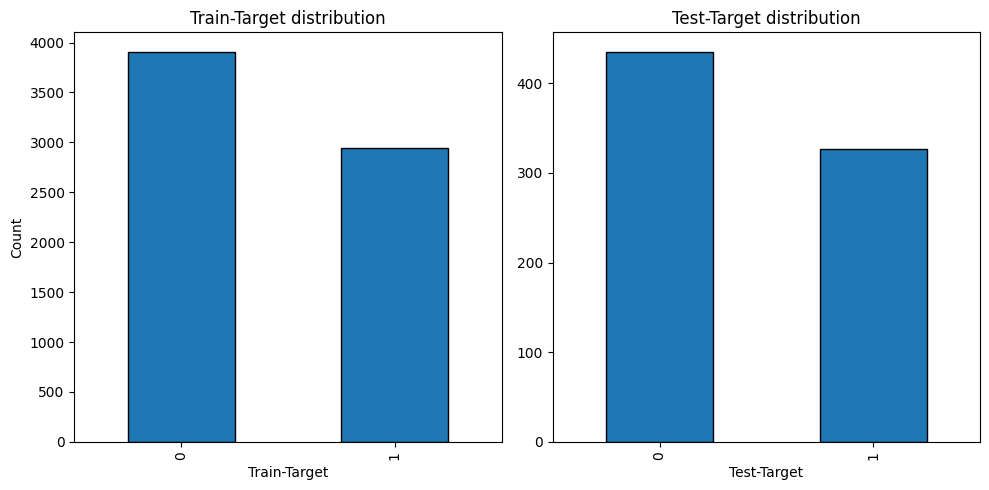

In [6]:
#Bar plots  for taget
fig, axes  = plt.subplots(1, 2, figsize=(10,5))

# Train plot
y_train.value_counts().plot(kind='bar', edgecolor='black', ax=axes[0])
axes[0].set_title("Train-Target distribution")
axes[0].set_xlabel("Train-Target")
axes[0].set_ylabel("Count")

# Test plot
y_test.value_counts().plot(kind='bar', edgecolor='black', ax=axes[1])
axes[1].set_title("Test-Target distribution")
axes[1].set_xlabel("Test-Target")


plt.tight_layout()
plt.show()

#### **The dataset has mild to low imbalance with less than 20% differnce between classes 0 & 1.**

####**- Target 0 < 60%**
####- **Target 1 > 40%**


## 2. Dataset processsing

In [7]:
#Dropping "id", "location"
X_train = X_train.drop(columns=["id", "location"], axis=1)
X_test = X_test.drop(columns=["id", "location"], axis=1)

#Filling Nan values
X_train["keyword"] = X_train["keyword"].fillna("null")
X_test["keyword"] = X_test["keyword"].fillna("null")

#Columns concatenation
X_train["inputs"] = X_train['keyword'] + " " + X_train['text']
X_test["inputs"] = X_test['keyword'] + " " + X_test['text']


display(X_train.head())
print('\n')
display(X_test.head())

,keyword,text,inputs
6669,threat,Meek Mill responds to DrakeÛªs OVO Fest set w...,threat Meek Mill responds to DrakeÛªs OVO Fes...
3940,flood,survived the plague\nfloated the flood\njust p...,flood survived the plague\nfloated the flood\n...
7217,weapons,#Kick Hendrixonfire @'=BLACKCATS= | BIG NOOB ...,weapons #Kick Hendrixonfire @'=BLACKCATS= | B...
2234,deluge,Vince McMahon once again a billionaire: I reme...,deluge Vince McMahon once again a billionaire:...
4233,hazardous,Is it possible to sneak into a hospital so I c...,hazardous Is it possible to sneak into a hospi...


,keyword,text,inputs
604,bioterror,#FedEx no longer to transport bioterror germs ...,bioterror #FedEx no longer to transport bioter...
5374,panic,Panic over: Patient in Alabama tests negative ...,panic Panic over: Patient in Alabama tests neg...
3022,dust%20storm,New Mad Max Screenshots Show Off a Lovely Dust...,dust%20storm New Mad Max Screenshots Show Off ...
3357,evacuated,Rocky fire in Northern California swells to 60...,evacuated Rocky fire in Northern California sw...
4726,lava,@YoungHeroesID Lava Blast &amp; Power Red @die...,lava @YoungHeroesID Lava Blast &amp; Power Red...


## 3. Text Processing

In [ ]:
# Removing: #, @ ,$, %, ^, &, *, (), -, !


## 4. Numpy Arrays

In [8]:
#Train set
train_input = X_train['inputs'].to_numpy()
train_taget = y_train.to_numpy()

#Evaluation set
test_input = X_test['inputs'].to_numpy()
test_target = y_test.to_numpy()

## 5. tf-idf

In [9]:
#Tokenization
vectorizer = TfidfVectorizer()

train_tokens = vectorizer.fit_transform(train_input)
test_tokens = vectorizer.transform(test_input)

print(train_tokens.shape)
print(test_tokens.shape)

print(train_tokens)


(6851, 20199)
(762, 20199)
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 101952 stored elements and shape (6851, 20199)>
  Coords	Values
  (0, 17578)	0.4956267394433029
  (0, 11421)	0.2432130962519636
  (0, 11607)	0.2716928973941074
  (0, 14909)	0.2770035233735556
  (0, 17734)	0.08619232484585826
  (0, 5736)	0.2372927043339243
  (0, 20169)	0.19045239346642615
  (0, 13130)	0.30088305104601154
  (0, 6865)	0.30088305104601154
  (0, 15790)	0.20609024874903592
  (0, 19329)	0.1263996119432929
  (0, 19115)	0.31485167926933144
  (0, 8703)	0.060349284183178725
  (0, 4240)	0.056815619452815554
  (0, 14324)	0.31485167926933144
  (1, 7058)	0.3425715466440175
  (1, 17004)	0.18294255128258577
  (1, 17444)	0.18900077310471874
  (1, 13653)	0.24835865550247707
  (1, 7056)	0.24179701418623512
  (1, 9865)	0.12301254429121214
  (1, 13415)	0.2687409750963535
  (1, 13072)	0.1561579700114226
  (1, 8309)	0.23643576286234536
  (1, 1385)	0.23190288945540988
  :	:
  (6849, 12311)	0.20420889780306

## 6.Gausssian Naive Bayes model

In [10]:
#Model Training
gnb = GaussianNB()
gnb.fit(train_tokens.toarray(), train_taget)

#Predictioning
train_pred = gnb.predict(train_tokens.toarray())
test_pred = gnb.predict(test_tokens.toarray())

#Evaluation
train_acc = accuracy_score(train_taget, train_pred)
test_acc = accuracy_score(test_target, test_pred)

print(f"Train accuracy: {train_acc}")
print(f"Test accuracy: {test_acc}")

Train accuracy: 0.9550430594073858
Test accuracy: 0.6272965879265092
